In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy. integrate import solve_ivp
import pandas as pd

#fator_nuclear = pd.read_csv("fator_nuclear.csv",
#                    sep=";",
#                   decimal=",",
#                   header = None)
#no arquivo ";" separa dois números e "," é separador decimal, não tem cabeçalho,
#tem q avisar pro leitor q a primeira linha já é dado.

#nlrp3_o = pd.read_csv("nlrp3_o.csv",
#                      sep=";",
#                      decimal=",",
#                      header = None)

In [ ]:
#Parâmetros NF-kB
nfkb0 = 0.25
gammaNF = 2
NF_50 = 0.3
h = 0.55
s = 0.8
tau = 10
S1 = 1
#t = np.arange(0.000001, 300, 1)
#o t corresponde a um intervalo de 1 a 100, de 1 em 1
#diferente do range, assim dá pra lidar com float

#Parâmetros NLRP3
alpha1 = 0.07
S2 = 1
k1 = 0.7
delta1 = 0.002
k2 = 1

#Parâmetros ASC
k3 = 0.04
a = 1
b = 2
c = 1000

#Caspase-1
k4 = 0.03
C1_50 = 0.3
gammaC1 = 2

#Gardermina
G = 0.08
#G = G * k6 (k6 = 1/min)
#Valor anterior de G: 0.1

#Citocinas
alpha3 = 0.06
alpha4 = 1
alpha5 = 1
k5 = 1
delta2 = 0.004

In [ ]:
#Função para determinar NF-kB
def nfkbn(t):
  #np.where para aplicar a lógica condicional elemento a elemento, p n dar aquele erro de valor único
  #se t for 0, retorna 0.25, senao, calcula a fórmula

  t_log = np.where(t == 0, 1.0, t)
  #isso quer dizer: p cada elemento, se t==0, use 1; senao, use t

  resultado = S1 * h * np.exp(-(np.log(t_log/tau) ** 2) / s) + nfkb0

  return np.where(t == 0, 0.25, resultado)


In [ ]:
#tempo_artigo = fator_nuclear.iloc[:, 0].to_numpy()
#nfkbn_artigo = fator_nuclear.iloc[:, 1].to_numpy()

#iloc = integer location -> iloc[linhas, colunas]
# : significa que é pra pegar tudo

#nfkbn_modelo = nfkbn(tempo_artigo)
#aq tá recebendo o vetor inteiro com os tempos da planilha

In [ ]:
#plt.plot(tempo_artigo, nfkbn_modelo, color = "green", label="Modelo")
#plt.scatter(tempo_artigo, nfkbn_artigo, color = "blue", s = 10, label="Artigo")

#plt.xlabel("Tempo")
#plt.ylabel("Concentração")
#plt.title("Comparação Modelo x Artigo")
#plt.legend()


In [ ]:
#Hill function
def hill(x, K, n):
  return (x**n) / (K**n + x**n)

In [ ]:
#Função sinalizadora de ASC

def sinal(NLRP3o, a, b, c):
  return 1/(1 + (((NLRP3o + a)/b) ** (-c)))

In [ ]:
#EDOS para o NLRP3

def dinamica_nlrp3(t, y):
  #def o q eu quero retornar como posições no array y
  NLRP3i = y[0]
  NLRP3a = y[1]
  NLRP3o = y[2]
  ASCf = y[3]
  ASCb = y[4]
  proC1 = y[5]
  C1 = y[6]
  proIL1b = y[7]
  IL1bc = y[8]
  IL1be = y[9]
  proIL18 = y[10]
  IL18c = y[11]
  IL18e = y[12]

  #nfkbn_barra = nfkbn(t) - nfkb0

  dNLRP3i_dt = (
      alpha1 * hill(nfkbn(t) - nfkb0, NF_50, gammaNF) - S2*k1*NLRP3i - delta1*NLRP3i
  )

  dNLRP3a_dt = (
      S2*k1*NLRP3i - k2*( NLRP3a**2) - delta1*NLRP3a
  )

  dNLRP3o_dt = (
      k2*(NLRP3a**2)
  )

  dASCf_dt = (
      -k3 * sinal(NLRP3o, a, b, c) * ASCf
  )

  dASCb_dt = (
      k3 * sinal(NLRP3o, a, b, c) * ASCf
  )

  dproC1_dt = (
      -k4 * ASCb * proC1
  )

  dC1_dt = (
      k4 * ASCb * proC1
  )

  dproIL1b_dt = (
      (hill(nfkbn(t) - nfkb0, NF_50, gammaNF)*alpha3) - (hill(C1, C1_50, gammaC1)*alpha4*proIL1b) - (delta2*proIL1b)
  )

  dIL1bc_dt = (
      (hill(C1, C1_50, gammaC1)*alpha4*proIL1b ) - (k5 *  G * IL1bc) - (delta2*IL1bc)
  )

  dIL1be_dt = (
      (k5 * G * IL1bc)
  )

  dproIL18_dt = (
      -(alpha5 * hill(C1, C1_50, gammaC1)) * proIL18
  )

  dIL18c_dt = (
      (alpha5 * hill(C1, C1_50, gammaC1) * proIL18 ) - (G * IL18c)
  )

  dIL18e_dt = (
      G * IL18c
  )

  #Aqui ela retorna as derivadas, dps eu preciso chamar o solve_ivp pra ter a resolução das EDOs
  return [dNLRP3i_dt, dNLRP3a_dt, dNLRP3o_dt, dASCf_dt, dASCb_dt, dproC1_dt, dC1_dt, dproIL1b_dt, dIL1bc_dt, dIL1be_dt, dproIL18_dt, dIL18c_dt, dIL18e_dt]


In [ ]:
#Resolução das EDOs

#Valores iniciais, respectivamente: NLRP3 inativo, ativo, oligomerizado, ASC livre e ligada
valores_iniciais = np.array([0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0]) #convertendo para array de floats
t_span = np.array([0.00, 300.0]) #convertendo para array de floats

solucao = solve_ivp(
    dinamica_nlrp3, t_span, valores_iniciais, method="BDF", rtol=1e-4,
    atol=1e-4)

In [ ]:
#Salvar os valores pra usar no outro arquivo

resultado = pd.DataFrame({
    "tempo": solucao.t,
    "NFkBn": nfkbn(solucao.t),
    "NLRP3i": solucao.y[0],
    "NLRP3a": solucao.y[1],
    "NLRP3o": solucao.y[2],
    "ASCf": solucao.y[3],
    "ASCb": solucao.y[4],
    "proC1": solucao.y[5],
    "C1": solucao.y[6],
    "proIL1b": solucao.y[7],
    "IL1bc": solucao.y[8],
    "IL1be": solucao.y[9],
    "proIL18": solucao.y[10],
    "IL18c": solucao.y[11],
    "IL18e": solucao.y[12]

})

resultado.to_csv("resultado_modelo.csv", index=False)


In [ ]:
#!ls -> pra listar os arquivos gerados

#pra baixar a planilha q criei:

#from google.colab import files

#files.download("resultado_modelo.csv")

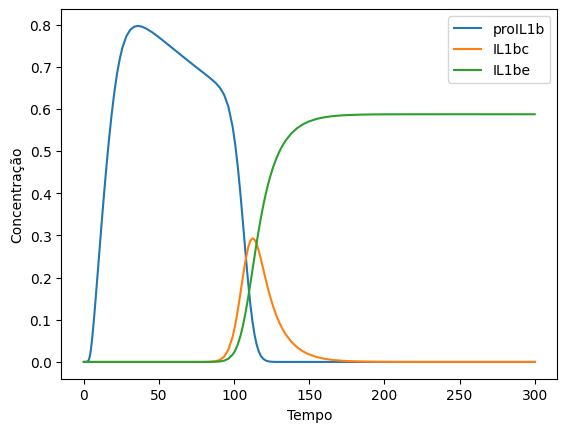

In [ ]:
#Gráfico 1L-1B
plt.plot(solucao.t, solucao.y[7], label = "proIL1b")
plt.plot(solucao.t, solucao.y[8], label = "IL1bc")
plt.plot(solucao.t, solucao.y[9], label = "IL1be")
plt.xlabel("Tempo")
plt.ylabel("Concentração")

plt.legend()


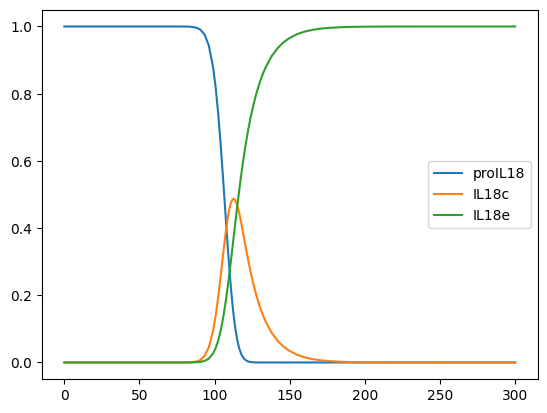

In [ ]:
#Gráfico IL-18

plt.plot(solucao.t, solucao.y[10], label = "proIL18")
plt.plot(solucao.t, solucao.y[11], label = "IL18c")
plt.plot(solucao.t, solucao.y[12], label = "IL18e")

plt.legend()

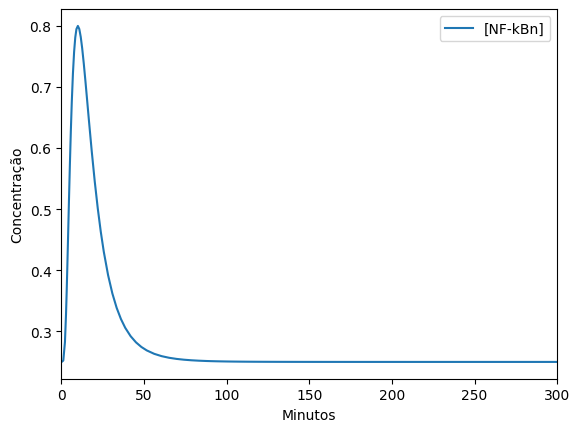

In [ ]:
#Gráfico NL-kB
x = solucao.t
y = nfkbn(x) #usar os tempos da solução (x)
plt.xlim(0, 300)
plt.plot(x, y, label="[NF-kBn]") #rótulo p/ legenda
plt.xlabel("Minutos")
plt.ylabel("Concentração")
plt.legend()
plt.show()

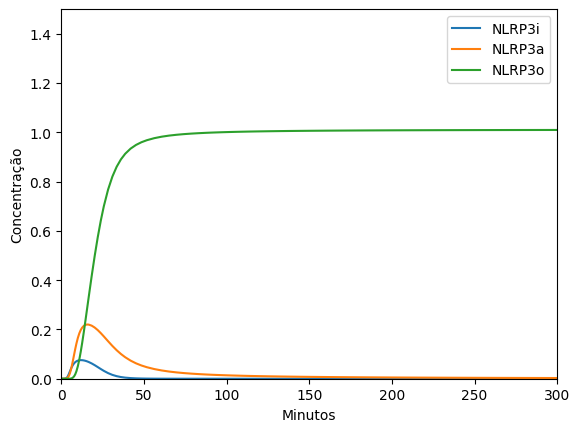

In [ ]:
#Gráfico NLRP3
plt.xlabel("Minutos")
plt.ylabel("Concentração")

plt.xlim(0, 300)
plt.ylim(0, 1.5)

plt.plot(solucao.t, solucao.y[0], label="NLRP3i")
plt.plot(solucao.t, solucao.y[1], label="NLRP3a")
plt.plot(solucao.t, solucao.y[2], label="NLRP3o")
plt.legend()

plt.show()


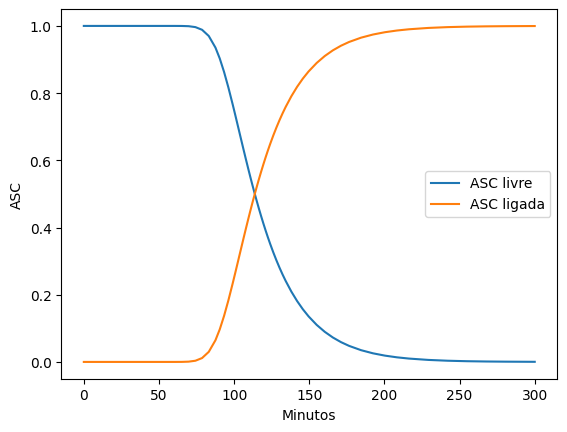

In [ ]:
#Gráfico ASC

plt.xlabel("Minutos")
plt.ylabel("ASC")

plt.plot(solucao.t, solucao.y[3], label ="ASC livre")
plt.plot(solucao.t, solucao.y[4], label="ASC ligada")

plt.legend()
plt.show()

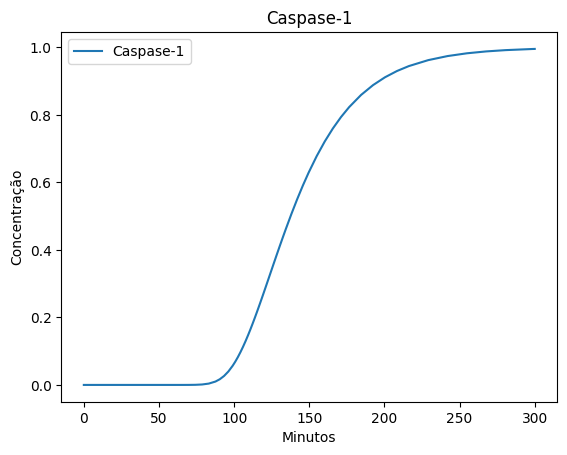

In [ ]:
#Gráfico Caspase-1

plt.plot(solucao.t, solucao.y[6], label="Caspase-1")
plt.legend()
plt.title("Caspase-1")
plt.xlabel("Minutos")
plt.ylabel("Concentração")
plt.show()

